# E03 · The Diffraction Limit
### From two blurred points to the information in an image

**Optics in 5 Minutes** · a self-contained, CPU-only learning lab · approximately 25 minutes.

**Prerequisites:** basic Python arrays, complex numbers, and the idea of a Fourier transform.

**Learning goals**
1. Predict how wavelength and numerical aperture affect the point spread function (PSF).
2. Distinguish the Rayleigh two-point criterion from the incoherent frequency cutoff.
3. Build and verify a PSF/OTF pair from a circular pupil.
4. Explain why regularization stabilizes inversion without measuring missing frequencies.

**Run:** in Colab choose **Runtime → Run all**. Locally, use a Python 3 Jupyter kernel.
The notebook installs missing numerical packages only if necessary. It does not mount Drive,
clone a repository, download data, or require a GPU, Manim, or TTS.

**Model:** equal mutually incoherent point emitters; ideal circular pupil; monochromatic,
in-focus scalar imaging. All distances are in object space. $\lambda_0$ is the **vacuum**
wavelength and $\mathrm{NA}=n\sin\theta$. Vector effects, aberrations, finite emitters,
and detector integration are omitted. High-NA behavior is a scalar teaching approximation.

In [1]:
import importlib.util
import subprocess
import sys

requirements = {"numpy": "numpy>=1.24,<3", "scipy": "scipy>=1.10,<2", "matplotlib": "matplotlib>=3.7,<4"}
missing = [spec for name, spec in requirements.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np
import scipy
from scipy.special import j1, jn_zeros
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

get_ipython().run_line_magic("matplotlib", "inline")

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
TEAL, ORANGE, INK = "#237c8c", "#b36e42", "#172f32"
RAYLEIGH_FACTOR = float(jn_zeros(1, 1)[0] / (2 * np.pi))
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)

Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Predict, then change a parameter

Start with two points 520 nm apart. Predict what happens when you:
- increase NA while keeping wavelength fixed;
- use a shorter wavelength while keeping NA fixed;
- enlarge the display without changing the optics.

Edit the next cell (or use its Colab controls), then rerun the following plot.
Lengths inside the calculations use **micrometres**: 1 μm = 1000 nm.

In [2]:
#@title Experiment parameters
wavelength_nm = 550 #@param {type:"slider", min:400, max:700, step:10}
NA = 0.65 #@param {type:"slider", min:0.2, max:0.95, step:0.01}
separation_nm = 520 #@param {type:"slider", min:100, max:2400, step:1}
display_zoom = 1.0 #@param {type:"slider", min:1, max:2.5, step:0.25}

assert 400 <= wavelength_nm <= 700 and 0.2 <= NA <= 0.95
assert 100 <= separation_nm <= 2400 and 1 <= display_zoom <= 2.5
lambda_um = wavelength_nm / 1000
d_um = separation_nm / 1000
d_rayleigh = RAYLEIGH_FACTOR * lambda_um / NA
fc = 2 * NA / lambda_um # incoherent intensity cutoff, cycles / micrometre
print(f"Rayleigh separation: {1000*d_rayleigh:.2f} nm")
print(f"Separation / Rayleigh: {d_um/d_rayleigh:.3f}")
print(f"Incoherent cutoff: {fc:.3f} cycles/μm; reciprocal cutoff period: {1000/fc:.2f} nm")

Rayleigh separation: 516.01 nm
Separation / Rayleigh: 1.008
Incoherent cutoff: 2.364 cycles/μm; reciprocal cutoff period: 423.08 nm


For a circular pupil, the **peak-normalized intensity** PSF is

$$h(r)=\left[\frac{2J_1(v)}{v}\right]^2,\qquad v=\frac{2\pi\,\mathrm{NA}\,r}{\lambda_0},\qquad h(0)=1.$$

The first zero of $J_1$ is approximately 3.831706, so the Airy first-zero radius is
$0.609835\lambda_0/\mathrm{NA}$. Rayleigh uses this as a reference separation for equally bright,
mutually incoherent points. It is a convention, not a universal boundary on inference.

The two **intensities add**. With coherent sources, complex fields and their relative phase would
need to be specified instead. Peak normalization compares shape; it does not compare photon
collection across NA.

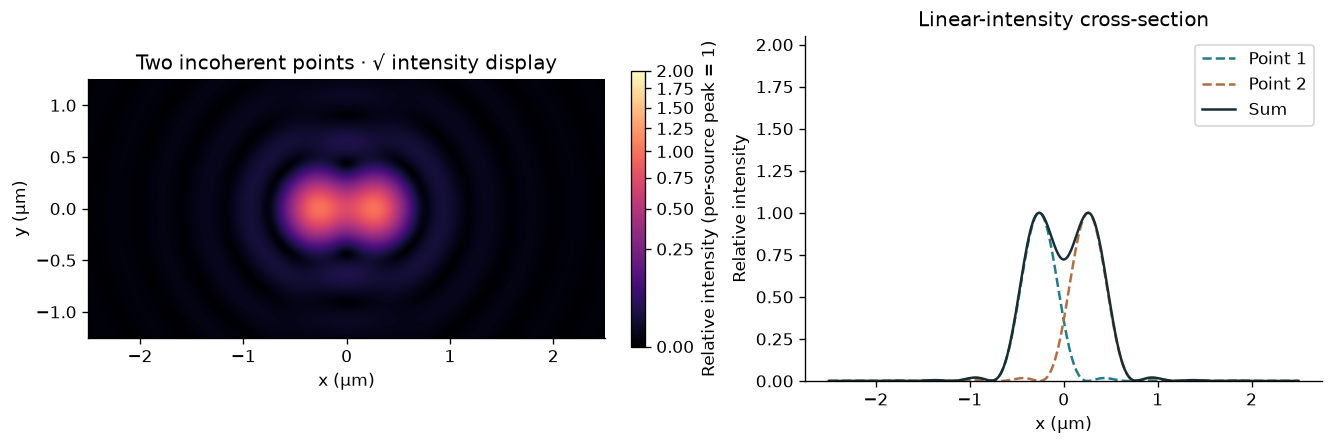

In [3]:
def airy_psf(r_um, na, wavelength_um):
    # Peak-normalized scalar circular-pupil intensity; radii in μm.
    v = 2 * np.pi * na * np.abs(np.asarray(r_um, dtype=float)) / wavelength_um
    amplitude = np.ones_like(v)
    np.divide(2 * j1(v), v, out=amplitude, where=v != 0)
    return amplitude**2

def circular_mtf(rho):
    # Normalized incoherent circular-pupil OTF (equal to MTF for this ideal pupil).
    q = np.clip(np.abs(np.asarray(rho, dtype=float)), 0, 1)
    return 2/np.pi * (np.arccos(q) - q*np.sqrt(np.maximum(0, 1-q*q)))

extent = 2.5 / display_zoom
x = np.linspace(-extent, extent, 501)
y = np.linspace(-extent/2, extent/2, 251)
X, Y = np.meshgrid(x, y)
image_pair = sum(airy_psf(np.hypot(X-s, Y), NA, lambda_um) for s in [-d_um/2, d_um/2])
left = airy_psf(x+d_um/2, NA, lambda_um)
right = airy_psf(x-d_um/2, NA, lambda_um)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
im = ax[0].imshow(image_pair, extent=[x[0], x[-1], y[0], y[-1]], origin="lower",
                  cmap="magma", norm=PowerNorm(gamma=.5, vmin=0, vmax=2))
ax[0].set(xlabel="x (μm)", ylabel="y (μm)", title="Two incoherent points · √ intensity display")
fig.colorbar(im, ax=ax[0], label="Relative intensity (per-source peak = 1)", shrink=.8)
ax[1].plot(x, left, "--", color=TEAL, label="Point 1")
ax[1].plot(x, right, "--", color=ORANGE, label="Point 2")
ax[1].plot(x, left+right, color=INK, label="Sum")
ax[1].set(xlabel="x (μm)", ylabel="Relative intensity", title="Linear-intensity cross-section", ylim=(0, 2.05))
ax[1].legend()
plt.show()

**Exercise 1.** Keep wavelength = 550 nm and separation = 520 nm. Compare NA = 0.4 and 0.8.
Write down both Rayleigh separations before looking at the plots. Then double only the display zoom.
Which physical quantity stays invariant?

<details><summary>Check your reasoning</summary>
The Rayleigh separations are about 839 nm and 419 nm. Doubling NA halves the Airy radius.
Display zoom only changes the displayed field of view. It leaves the physical PSF, separation/criterion
ratio, and cutoff unchanged. Cropping does not recover information.
</details>

## 2 · A cutoff is not a two-point distance

For a sinusoidal **intensity** object, the image contrast equals input contrast times

$$H(\rho)=\frac{2}{\pi}\left[\cos^{-1}\rho-\rho\sqrt{1-\rho^2}\right],\quad
\rho=|f|/f_c<1,\qquad f_c=\frac{2\,\mathrm{NA}}{\lambda_0}.$$

$H=0$ at and beyond $\rho=1$. The reciprocal cutoff period $\lambda_0/(2\mathrm{NA})$ is therefore
**not a period with useful nonzero image contrast at the boundary**. Contrast drops continuously.

Coherent imaging has a complex-field transfer function with cutoff $\mathrm{NA}/\lambda_0$;
intensity is computed after field propagation. Those are different input/output models.

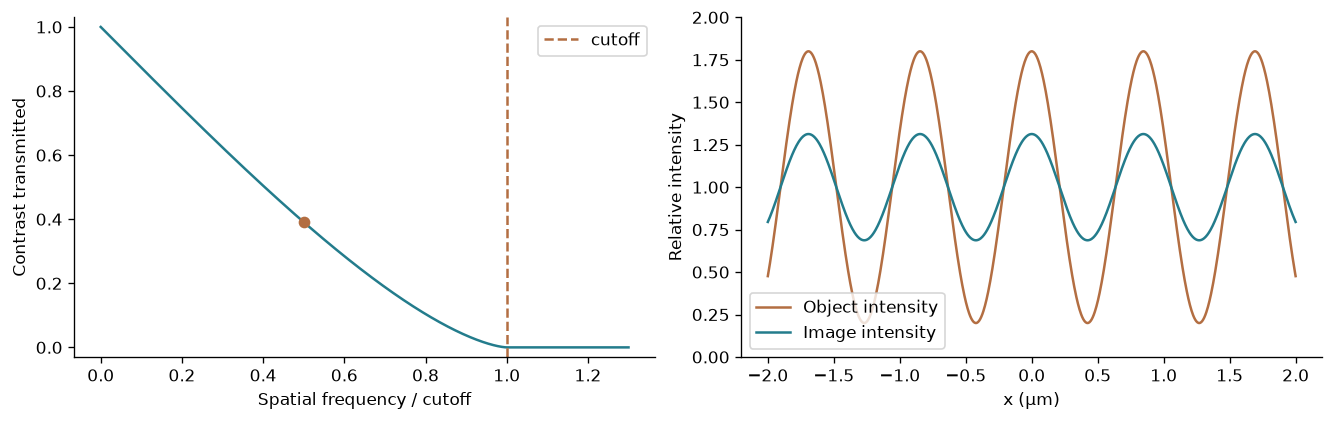

H = 0.3910; output contrast = 0.3128


In [4]:
#@title Pick a stripe frequency
frequency_over_cutoff = 0.5 #@param {type:"slider", min:0, max:1.3, step:0.01}
assert 0 <= frequency_over_cutoff <= 1.3
rho = np.linspace(0, 1.3, 501)
f_selected = frequency_over_cutoff * fc
H_selected = float(circular_mtf(frequency_over_cutoff))
xx = np.linspace(-2, 2, 1000)
obj_stripe = 1 + .8*np.cos(2*np.pi*f_selected*xx)
img_stripe = 1 + .8*H_selected*np.cos(2*np.pi*f_selected*xx)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
ax[0].plot(rho, circular_mtf(rho), color=TEAL)
ax[0].plot(frequency_over_cutoff, H_selected, "o", color=ORANGE)
ax[0].axvline(1, color=ORANGE, linestyle="--", label="cutoff")
ax[0].set(xlabel="Spatial frequency / cutoff", ylabel="Contrast transmitted", ylim=(-.03, 1.03))
ax[0].legend()
ax[1].plot(xx, obj_stripe, color=ORANGE, label="Object intensity")
ax[1].plot(xx, img_stripe, color=TEAL, label="Image intensity")
ax[1].set(xlabel="x (μm)", ylabel="Relative intensity", ylim=(0, 2))
ax[1].legend()
plt.show()
print(f"H = {H_selected:.4f}; output contrast = {0.8*H_selected:.4f}")
if frequency_over_cutoff == 0:
    print("At f=0 the pattern is uniform; H(0)=1 is the DC limit, not a measurable stripe contrast.")

**Exercise 2.** Predict the contrast transmission at $f=0.5f_c$, $f=f_c$, and $f=1.2f_c$.
Is the reciprocal cutoff period the same as the Rayleigh separation?

<details><summary>Check your reasoning</summary>
The values are approximately 0.391, 0, and 0. The two lengths use different test objects and criteria:
periodic intensity versus equal incoherent point sources. Rayleigh uses approximately 0.61 λ₀/NA;
the reciprocal cutoff uses 0.5 λ₀/NA.
</details>

## 3 · Build the PSF from the aperture

A circular pupil is a disk in spatial-frequency space. Its inverse Fourier transform gives
the amplitude impulse response. Squaring its magnitude gives the incoherent intensity PSF.

For convolution we normalize the PSF to **unit sum**, so a constant object retains its intensity.
This differs from peak normalization in the two-point display. Arrays below use native FFT order
(zero frequency / PSF origin at index [0,0]); `fftshift` is used only for plotting.

This reference grid fixes λ₀ = 1 μm and NA = 0.5 so the numerical verification remains reproducible
when you change the earlier sliders. The dimensionless shape is universal in this model.

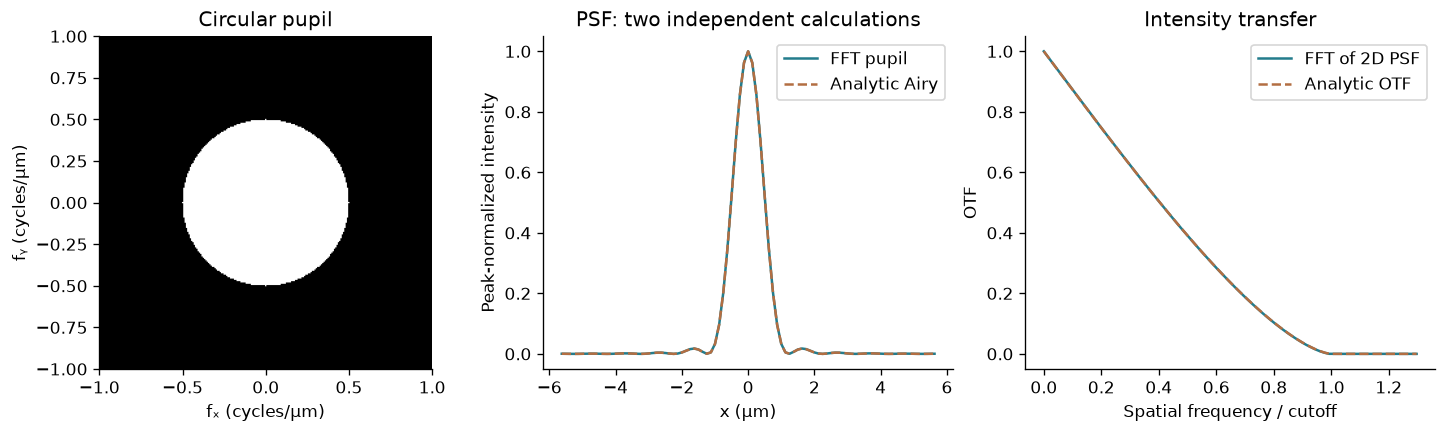

In [5]:
n, dx_um = 1024, 0.125
lambda_ref, na_ref = 1.0, 0.5
freq = np.fft.fftfreq(n, d=dx_um)
FX, FY = np.meshgrid(freq, freq)
pupil = (np.hypot(FX, FY) <= na_ref/lambda_ref).astype(float)
amplitude_psf = np.fft.ifft2(pupil)
psf = np.abs(amplitude_psf)**2
psf /= psf.sum()
otf = np.fft.fft2(psf).real
fc_ref = 2*na_ref/lambda_ref
otf_analytic = circular_mtf(np.hypot(FX, FY)/fc_ref)

x_ref = (np.arange(n)-n//2)*dx_um
psf_centered = np.fft.fftshift(psf)
half = 45
sl = slice(n//2-half, n//2+half+1)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
ax[0].imshow(np.fft.fftshift(pupil), extent=[freq.min(), freq.max(), freq.min(), freq.max()], origin="lower", cmap="Greys_r")
ax[0].set(xlim=(-1, 1), ylim=(-1, 1), xlabel="fₓ (cycles/μm)", ylabel="fᵧ (cycles/μm)", title="Circular pupil")
ax[1].plot(x_ref[sl], psf_centered[n//2, sl]/psf.max(), label="FFT pupil", color=TEAL)
ax[1].plot(x_ref[sl], airy_psf(x_ref[sl], na_ref, lambda_ref), "--", label="Analytic Airy", color=ORANGE)
ax[1].set(xlabel="x (μm)", ylabel="Peak-normalized intensity", title="PSF: two independent calculations")
ax[1].legend()
positive = (freq>=0)&(freq<=1.3*fc_ref)
ax[2].plot(freq[positive]/fc_ref, otf[0, positive], color=TEAL, label="FFT of 2D PSF")
ax[2].plot(freq[positive]/fc_ref, otf_analytic[0, positive], "--", color=ORANGE, label="Analytic OTF")
ax[2].set(xlabel="Spatial frequency / cutoff", ylabel="OTF", title="Intensity transfer")
ax[2].legend()
plt.show()

### Verify rather than trust the plot

The OTF is also the normalized **autocorrelation of the pupil**. Check several shifts directly.
The pupil is far smaller than the frequency grid, so the shifts below do not introduce boundary overlap.
Finite pupil rasterization explains the small difference from the continuous circular-pupil formula.

**Do not Fourier-transform only the central 1D Airy cross-section to obtain this OTF.**
The correct 1D kernel for a stripe object is the **line-spread function**, found by integrating
the full 2D PSF along the perpendicular coordinate.

In [6]:
assert np.isclose(airy_psf(0, .5, 1), 1)
assert np.isclose(float(airy_psf(RAYLEIGH_FACTOR/.5, .5, 1)), 0, atol=1e-25)
assert np.isclose(float(circular_mtf(.5)), .3910022189557706)
assert np.allclose(circular_mtf([0, 1, 1.2]), [1, 0, 0])
assert np.isclose(psf.sum(), 1) and np.isclose(otf[0, 0], 1)
assert np.allclose(np.fft.ifft2(np.fft.fft2(np.ones_like(psf))*otf).real, 1)
otf_error = np.max(np.abs(otf-otf_analytic))
airy_error = np.max(np.abs(psf_centered[n//2, sl]/psf.max()-airy_psf(x_ref[sl], na_ref, lambda_ref)))
assert otf_error < .005, otf_error
assert airy_error < .005, airy_error
overlap_errors = []
for shift in [0, 15, 32, 64, 100, 128]:
    direct_overlap = np.sum(pupil*np.roll(pupil, shift, axis=1))/np.sum(pupil**2)
    overlap_errors.append(abs(direct_overlap-otf[0, shift]))
assert max(overlap_errors) < 1e-12
line_spread = psf.sum(axis=0)
assert np.allclose(np.fft.fft(line_spread), otf[0], atol=1e-12)
print(f"Maximum OTF error: {otf_error:.6f}; Airy-profile error: {airy_error:.6f}")
print(f"Maximum pupil-overlap error: {max(overlap_errors):.2e}")
print("All normalization, cutoff, analytic-agreement, and autocorrelation checks passed.")

Maximum OTF error: 0.000942; Airy-profile error: 0.000396
Maximum pupil-overlap error: 1.11e-16
All normalization, cutoff, analytic-agreement, and autocorrelation checks passed.


## 4 · Can computation undo the blur?

Let the object be a periodic intensity pattern, invariant along y. We use the **analytic 2D OTF
slice at fᵧ = 0** to filter its x frequencies. This is equivalent to convolution with the line-spread
function—not the central Airy cross-section. A periodic domain makes the FFT boundary assumption explicit.

The object contains one frequency inside the passband and another beyond the cutoff. Add seeded
Gaussian measurement noise. Direct inversion divides by small H and amplifies noise.
A regularized filter uses $G=H^*/(|H|^2+K)$.

Here **K is a chosen regularization parameter**, not a measured noise variance or automatically 1/SNR.
This form is a constant-noise-to-signal Wiener approximation. It is zero wherever H is zero.

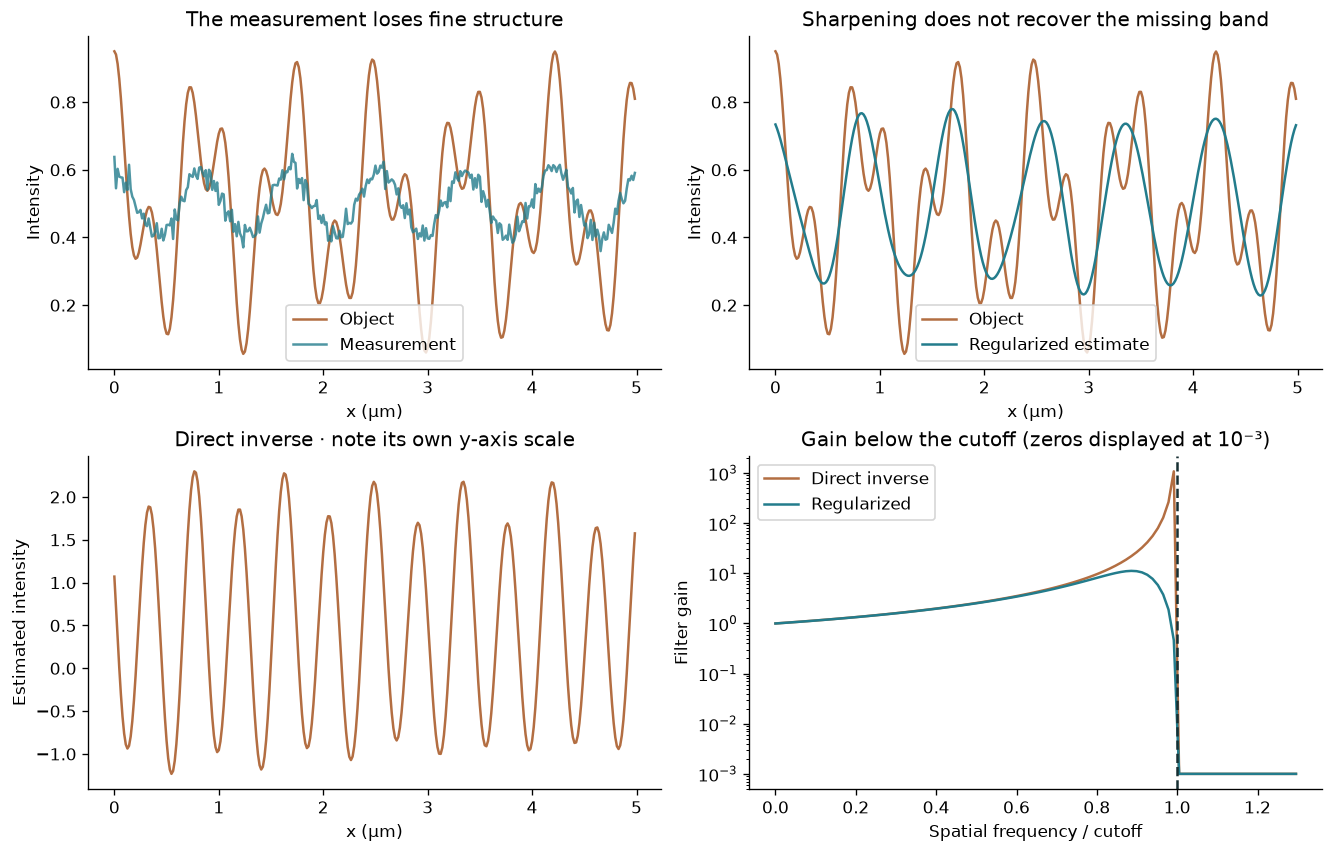

Object frequencies: 0.502 fc and 1.203 fc
Mean squared error: direct = 0.7404; regularized = 0.02088


In [7]:
#@title Inversion parameters
noise_std = 0.02 #@param {type:"slider", min:0, max:0.1, step:0.005}
regularization_K = 0.002 #@param {type:"number"}
assert noise_std >= 0 and regularization_K > 0

samples, length_um = 2048, 32.0
xx = np.arange(samples)*length_um/samples
ff = np.fft.fftfreq(samples, d=length_um/samples)
fc_demo = 2*.65/.55
k_low = max(1, round(.5*fc_demo*length_um))
k_high = round(1.2*fc_demo*length_um)
f_low, f_high = k_low/length_um, k_high/length_um # exact DFT bins: no spectral leakage
object_intensity = .5 + .25*np.cos(2*np.pi*f_low*xx) + .2*np.cos(2*np.pi*f_high*xx)
H = circular_mtf(np.abs(ff)/fc_demo)
blurred = np.fft.ifft(np.fft.fft(object_intensity)*H).real
rng = np.random.default_rng(3)
measurement = blurred + rng.normal(0, noise_std, samples)
measured_spectrum = np.fft.fft(measurement)

inverse_gain = np.zeros_like(H)
np.divide(1, H, out=inverse_gain, where=H>1e-8)
G = H/(H**2+regularization_K)
naive = np.fft.ifft(measured_spectrum*inverse_gain).real
regularized = np.fft.ifft(measured_spectrum*G).real

fig, ax = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
view = xx<5
ax[0,0].plot(xx[view], object_intensity[view], color=ORANGE, label="Object")
ax[0,0].plot(xx[view], measurement[view], color=TEAL, label="Measurement", alpha=.8)
ax[0,0].set(title="The measurement loses fine structure", xlabel="x (μm)", ylabel="Intensity")
ax[0,0].legend()
ax[0,1].plot(xx[view], object_intensity[view], color=ORANGE, label="Object")
ax[0,1].plot(xx[view], regularized[view], color=TEAL, label="Regularized estimate")
ax[0,1].set(title="Sharpening does not recover the missing band", xlabel="x (μm)", ylabel="Intensity")
ax[0,1].legend()
ax[1,0].plot(xx[view], naive[view], color=ORANGE)
ax[1,0].set(title="Direct inverse · note its own y-axis scale", xlabel="x (μm)", ylabel="Estimated intensity")
pos = (ff>=0)&(ff<=1.3*fc_demo)
ax[1,1].semilogy(ff[pos]/fc_demo, np.maximum(inverse_gain[pos], 1e-3), color=ORANGE, label="Direct inverse")
ax[1,1].semilogy(ff[pos]/fc_demo, np.maximum(G[pos], 1e-3), color=TEAL, label="Regularized")
ax[1,1].axvline(1, color=INK, linestyle="--")
ax[1,1].set(title="Gain below the cutoff (zeros displayed at 10⁻³)", xlabel="Spatial frequency / cutoff", ylabel="Filter gain")
ax[1,1].legend()
plt.show()
print(f"Object frequencies: {f_low/fc_demo:.3f} fc and {f_high/fc_demo:.3f} fc")
print(f"Mean squared error: direct = {np.mean((naive-object_intensity)**2):.4g}; regularized = {np.mean((regularized-object_intensity)**2):.4g}")
assert H[k_high] == 0 and G[k_high] == 0
assert abs(np.fft.fft(regularized)[k_high]/samples) < 1e-12

**Exercise 3.** Increase K by a factor of 10. Describe the trade-off between noise and contrast.
Then set the noise to zero. Does direct inversion restore the high-frequency object component?

<details><summary>Check your reasoning</summary>
Larger K suppresses noise amplification but also biases/suppresses measured signal components.
Even without noise, the out-of-band component remains absent because H is zero there.
Additional measurements or prior assumptions can constrain a reconstruction, but those supply
information beyond the single measurement modeled here.
</details>

## 5 · A short lab report

Record predictions before changing parameters. Submit:
1. Two profiles with different NA values and unchanged λ₀ and source separation.
2. The corresponding Rayleigh separation and incoherent cutoff, with units.
3. A sentence explaining what display zoom changes and what it leaves unchanged.
4. A regularized reconstruction with the chosen K and an explanation of its missing band.

**Suggested assessment (10 points):** prediction and controlled comparison (3); correct formulas,
units, and distinction between criteria (3); interpretation of noise/regularization (3); clear figure labels (1).

**Optional extension:** apply a phase aberration to the pupil. Compare the PSF with an ideal pupil
at the same NA. The general OTF may now be complex; distinguish OTF from its magnitude, the MTF.

## References and reproducibility

- [Nikon MicroscopyU: Resolution](https://www.microscopyu.com/microscopy-basics/resolution)
- [Nikon MicroscopyU: Modulation Transfer Function](https://www.microscopyu.com/microscopy-basics/modulation-transfer-function)
- [TU Delft: Advanced Optical Imaging, incoherent imaging](https://qiweb.tudelft.nl/aoi/incoherentimaging/incoherentimaging/)
- [Optics in 5 Minutes source](https://github.com/Vandermode/optics-in-5-minutes-course)

The browser lesson uses the same analytic equations and parameter defaults, with a tabulated Airy
function to keep interaction fast. This notebook evaluates Bessel functions directly with SciPy and
independently checks the Fourier-optics construction. Numerical noise uses seed 3. No external datasets.